# 01 - Data acquisition & exploratory data analysis
**Dataset:** UCI Heart Disease, all four collection sites (Cleveland, Hungary, Switzerland,
VA Long Beach) = 920 patients, 13 clinical features, diagnosis `num` 0-4.

Design decision: most published solutions use the 303-row Cleveland file only. Using all four
sites triples the data and forces the pipeline to deal with the **real missingness** that a
production system would face (several sites never measured `ca`, `thal`, `slope`).

In [1]:
import os, sys, warnings
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
from heart import config
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

## 1. Acquire
`heart.data.download()` fetches the four `processed.*.data` files (cached in `data/raw/`).

In [2]:
from heart.data import download, load_raw, clean
paths = download()
raw = load_raw()
print(raw.shape)
raw.head()

(920, 15)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,site
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,cleveland
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,cleveland
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,cleveland
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,cleveland
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,cleveland


## 2. Data quality audit of the raw files

In [3]:
audit = pd.DataFrame({
    "missing ('?')": raw.isna().sum(),
    "zeros": (raw == 0).sum(),
    "dtype": raw.dtypes.astype(str),
})
audit.loc[["chol", "trestbps", "ca", "thal", "slope"]]

,missing ('?'),zeros,dtype
chol,30,172,float64
trestbps,59,1,float64
ca,611,181,float64
thal,486,0,float64
slope,309,0,float64


In [4]:
print("rows with cholesterol == 0 by site:")
print(raw.loc[raw.chol == 0, "site"].value_counts())
print("\nduplicate rows:", raw.duplicated().sum())

rows with cholesterol == 0 by site:
site
switzerland    123
va              49
Name: count, dtype: int64



duplicate rows: 2


**Findings**
* `?` is the missing marker - parsed to NaN.
* `chol == 0` (172 rows: 123 Switzerland, 49 VA - Switzerland never recorded cholesterol) and `trestbps == 0` are physiologically impossible -> treated as missing.
* `num` is 0-4 severity; the task is binary, so target = `num > 0`.
* 2 exact duplicate rows are dropped.

Imputation is **not** done here - it lives inside the sklearn pipeline so the identical logic runs at serving time.

## 3. Clean

In [5]:
df = clean(raw)
df.to_csv(config.CLEAN_CSV, index=False)
print(df.shape, "positive rate = %.1f%%" % (100 * df.target.mean()))
df.describe().T.round(2)

(918, 15)

 positive rate = 55.3%


,count,mean,std,min,25%,50%,75%,max
age,918.0,53.51,9.43,28.0,47.0,54.0,60.0,77.0
trestbps,858.0,132.29,18.53,80.0,120.0,130.0,140.0,200.0
chol,717.0,246.87,58.56,85.0,210.0,240.0,277.0,603.0
thalach,863.0,137.54,25.94,60.0,120.0,140.0,157.0,202.0
oldpeak,856.0,0.88,1.09,-2.6,0.0,0.5,1.5,6.2
ca,309.0,0.68,0.94,0.0,0.0,0.0,1.0,3.0
sex,918.0,0.79,0.41,0.0,1.0,1.0,1.0,1.0
fbs,828.0,0.17,0.37,0.0,0.0,0.0,0.0,1.0
exang,863.0,0.39,0.49,0.0,0.0,0.0,1.0,1.0
cp,918.0,3.25,0.93,1.0,3.0,4.0,4.0,4.0


## 4. Visual EDA
All figures are produced by `heart.eda` (also run in CI) and saved to `reports/figures/eda/`.

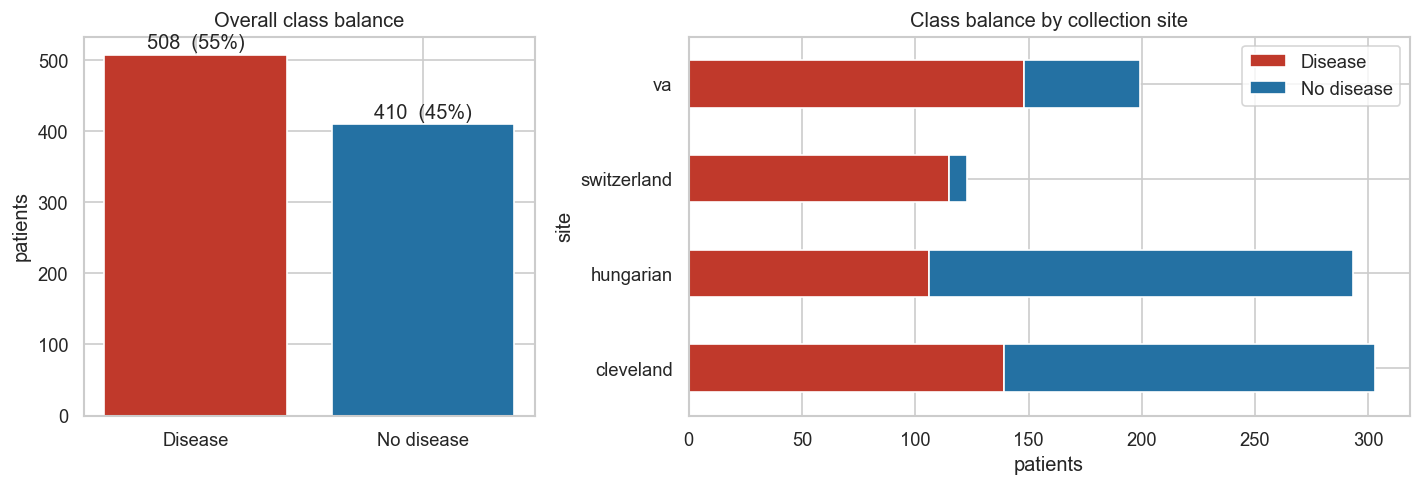

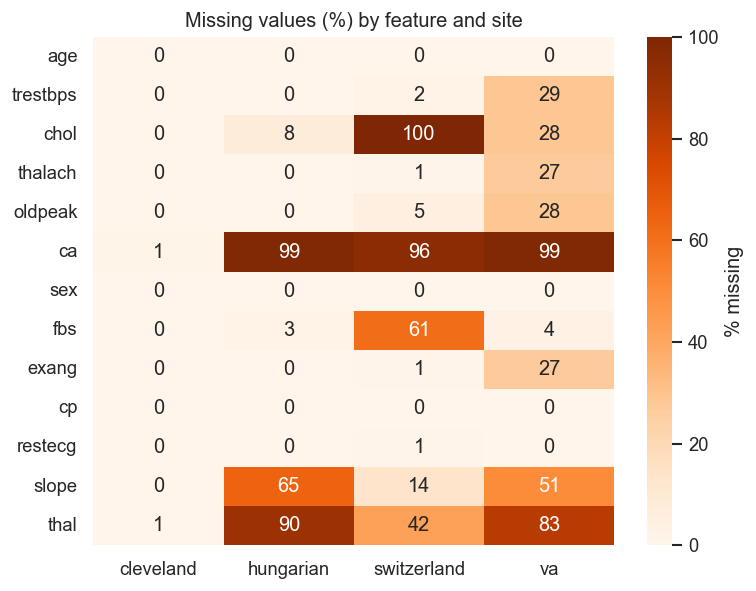

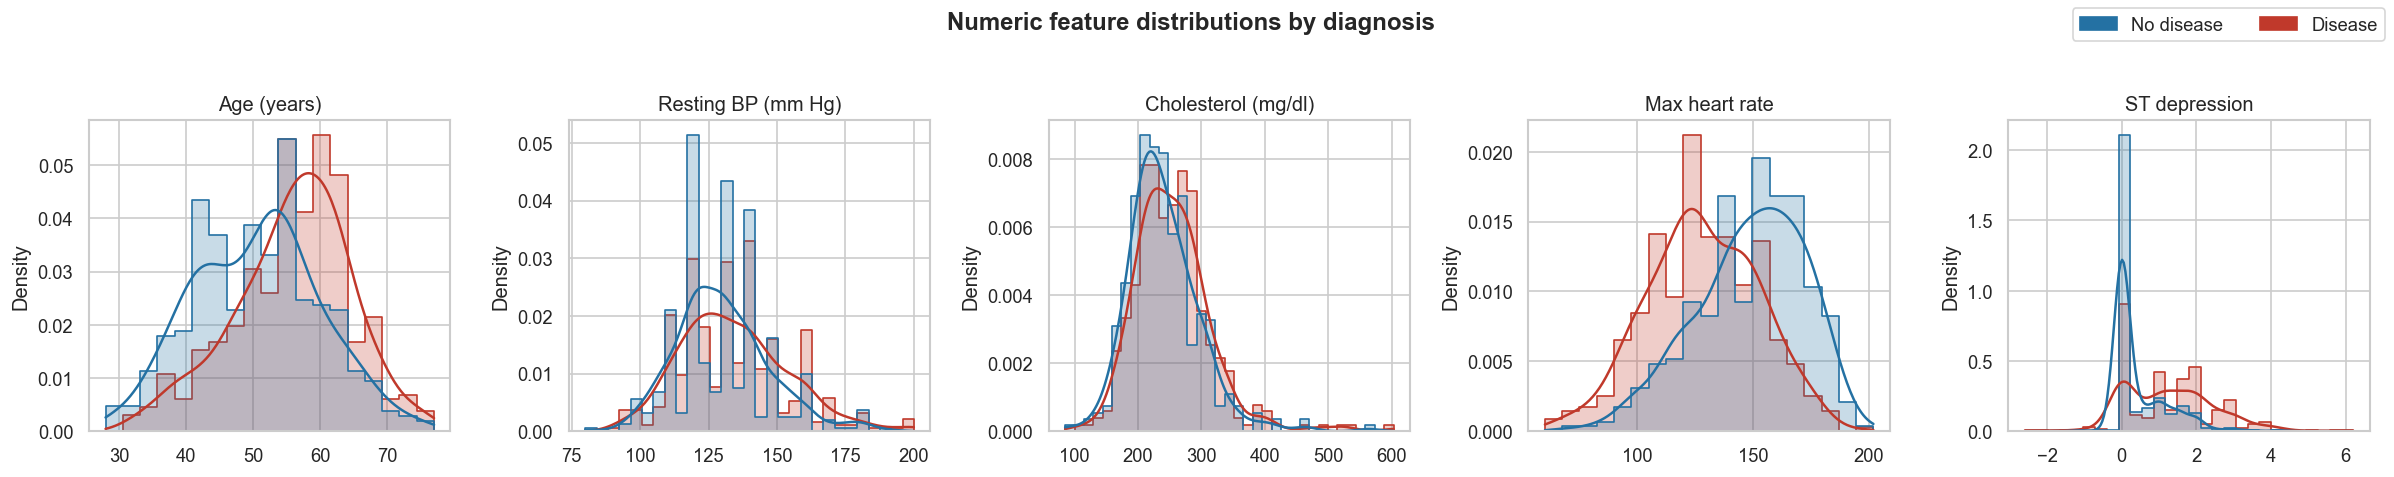

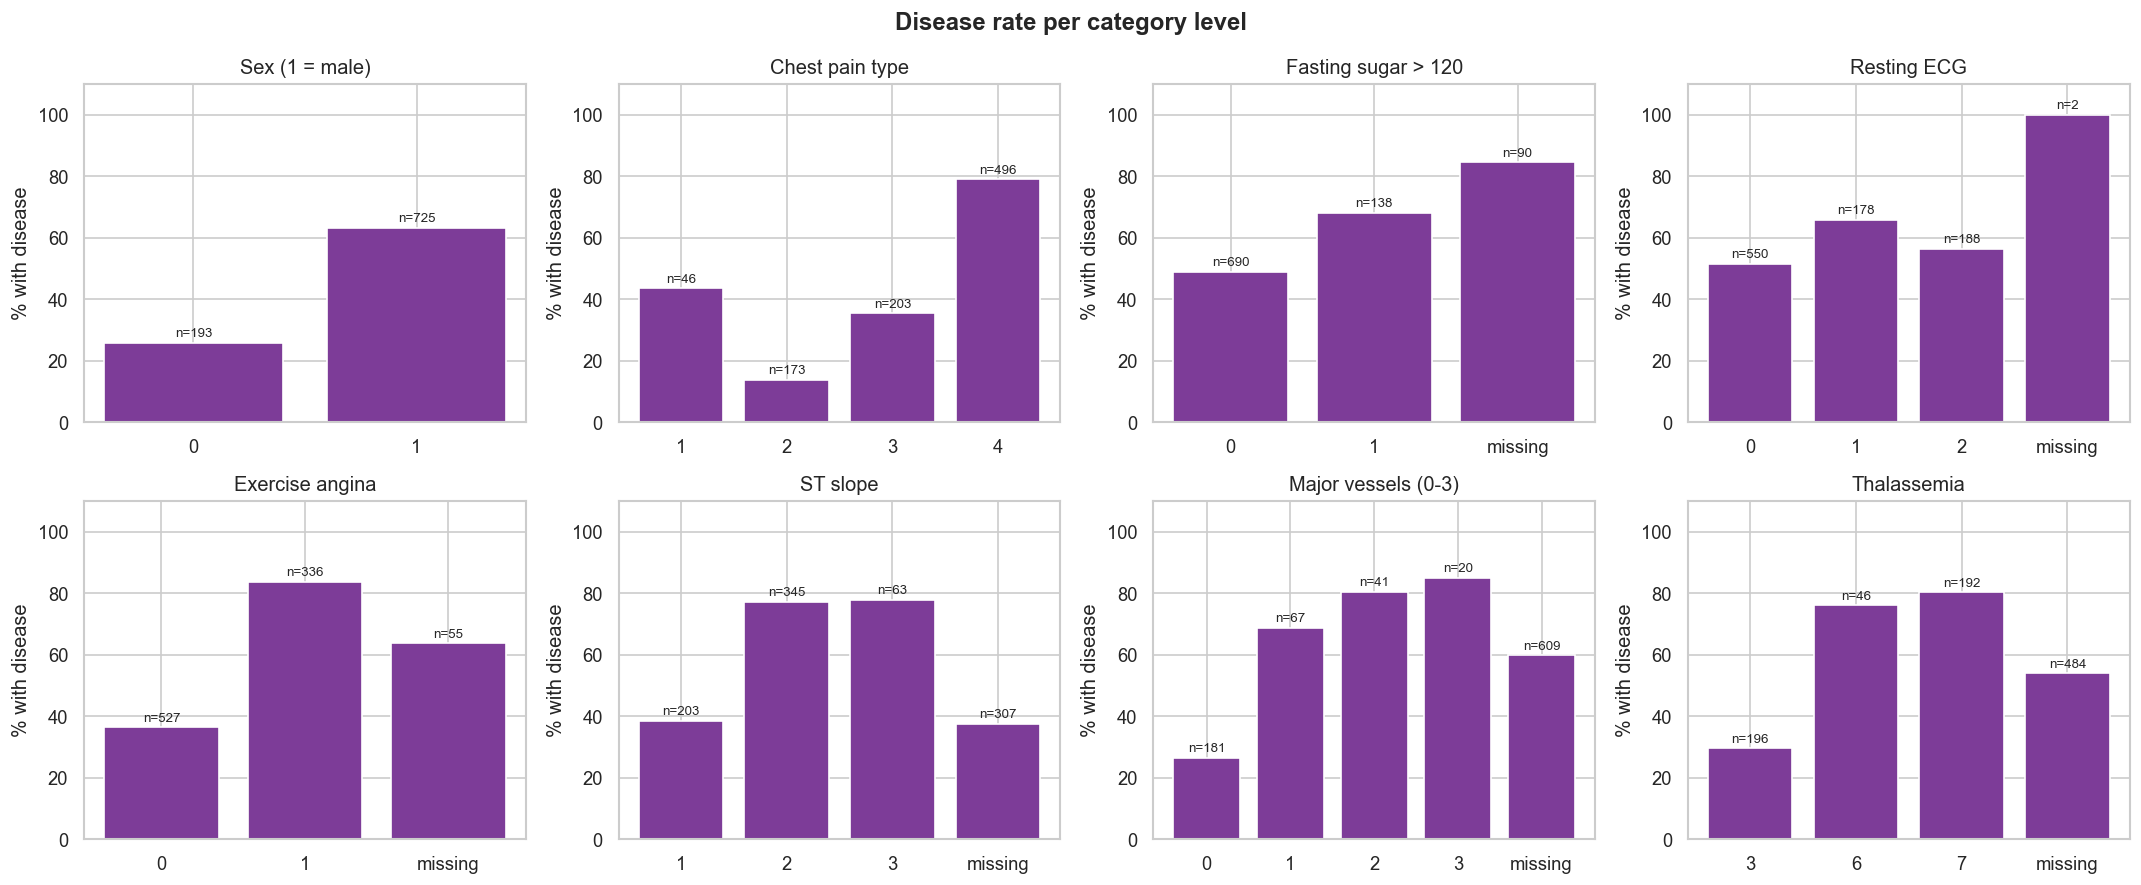

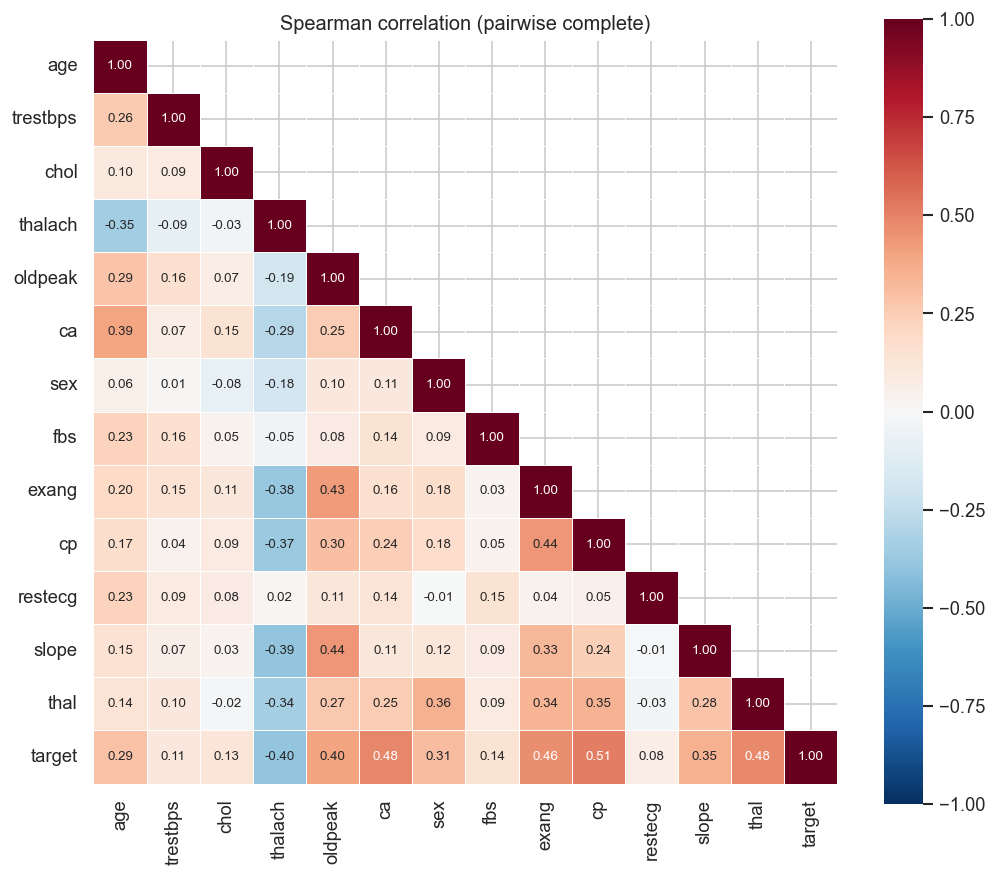

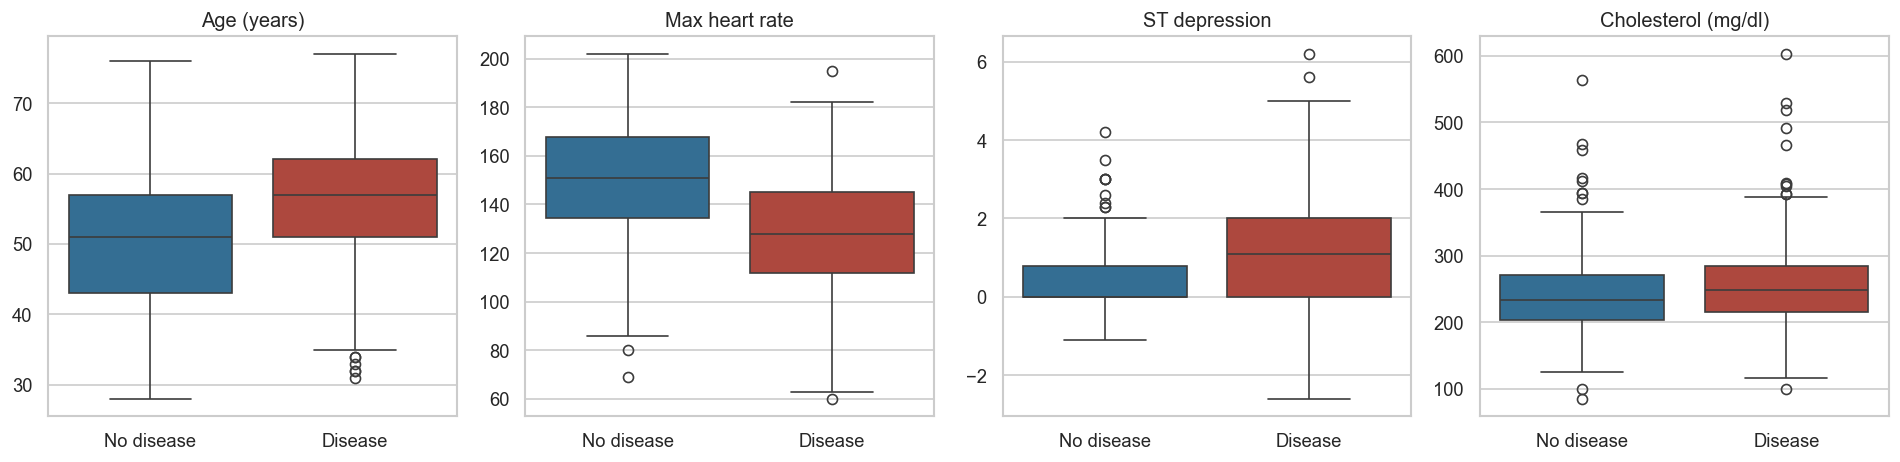

In [6]:
from heart import eda
figs = eda.run_all()
for f in figs:
    display(Image(f))

## 5. Key observations
| Observation | Consequence for modelling |
|---|---|
| Classes are reasonably balanced overall (55 % / 45 %) but prevalence differs strongly by site (Switzerland ~93 % positive) | Stratified splits; `site` is **excluded** from features - it would leak collection-centre prevalence and is not available at inference time |
| `ca` 66 %, `thal` 53 %, `slope` 33 % missing, concentrated in non-Cleveland sites | Median / constant imputation **plus missing-indicator flags** - missingness itself carries signal |
| Asymptomatic chest pain (`cp = 4`), exercise angina, ST depression (`oldpeak`), flat/down ST slope are the strongest univariate risk factors | Kept as-is; categorical codes one-hot encoded |
| `thalach` (max heart rate) is negatively correlated with disease | Linear models should do well |
| Skewed `oldpeak`, outliers in `chol` | Standard scaling; tree models are robust to the rest |

In [7]:
df.groupby("site")[["age", "chol", "thalach", "oldpeak", "target"]].mean().round(2)

,age,chol,thalach,oldpeak,target
site,,,,,
cleveland,54.44,246.69,149.61,1.04,0.46
hungarian,47.82,250.85,139.06,0.59,0.36
switzerland,55.32,NaN,121.56,0.65,0.93
va,59.36,239.71,122.83,1.33,0.74
